In [1]:
import glob
import os

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
sns.set_theme()
pd.set_option("display.max_colwidth", None)
pd.set_option('display.max_rows', 10)

### Example random box Liver 

Original image: 


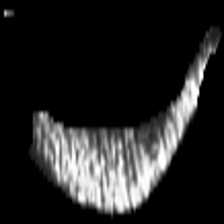

Box: 


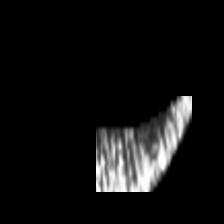

Context: 


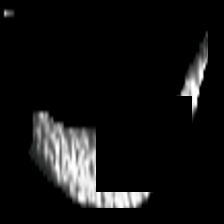

Image blend: 


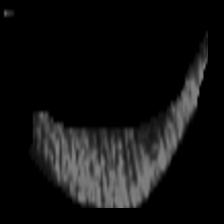

In [3]:
from PIL import Image

# Example of sampled boxes

image_name = "1_46"

original_image = Image.open(f"/media/vhondru/hdd/istoian/ijepa-anomaly-detection/experiments_hist_DIY/experiment_default_hyparams/results_valid/random_boxes_images/{image_name}_image.png")
box = Image.open(f"/media/vhondru/hdd/istoian/ijepa-anomaly-detection/experiments_hist_DIY/experiment_default_hyparams/results_valid/random_boxes_images/{image_name}_random_pixels_mask_image.png")
context = Image.open(f"/media/vhondru/hdd/istoian/ijepa-anomaly-detection/experiments_hist_DIY/experiment_default_hyparams/results_valid/random_boxes_images/{image_name}_context_image.png")

print("Original image: ")
display(original_image)

print("Box: ")
display(box)

print("Context: ")
display(context)

print("Image blend: ")
display(Image.blend(context, box, alpha=0.5))


### Example random box RESC 

In [4]:
from PIL import Image

# Example of sampled boxes

image_name = "15_39"

original_image = Image.open(f"/media/vhondru/hdd/istoian/ijepa-anomaly-detection/experiments_RESC/enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training_very_low_wd/results_valid/random_boxes_images/{image_name}_image.png")
box = Image.open(f"/media/vhondru/hdd/istoian/ijepa-anomaly-detection/experiments_RESC/enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training_very_low_wd/results_valid/random_boxes_images/{image_name}_random_pixels_mask_image.png")
context = Image.open(f"/media/vhondru/hdd/istoian/ijepa-anomaly-detection/experiments_RESC/enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training_very_low_wd/results_valid/random_boxes_images/{image_name}_context_image.png")

print("Original image: ")
display(original_image)

print("Box: ")
display(box)

print("Context: ")
display(context)

print("Image blend: ")
display(Image.blend(context, box, alpha=0.5))


FileNotFoundError: [Errno 2] No such file or directory: '/media/vhondru/hdd/istoian/ijepa-anomaly-detection/experiments_RESC/enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training_very_low_wd/results_valid/random_boxes_images/15_39_image.png'

# Results

In [5]:
metric_file_paths = glob.glob(os.path.join(
    "/media/vhondru/hdd/istoian/ijepa-anomaly-detection/experiments_*/*/**/",
    "*.csv"), recursive=True)

filtered_metric_file_paths = [metric_file_path for metric_file_path in metric_file_paths
                               if "Metrics" in metric_file_path]

metrics_dfs = []
for filtered_metric_file_path in filtered_metric_file_paths:
    metrics_dfs.append(pd.read_csv(filtered_metric_file_path))
concat_metrics_df = pd.concat(metrics_dfs).reset_index(drop=True)

concat_metrics_df["Avg(Image ROCAUC, Pixel ROCAUC)"] = concat_metrics_df.apply(lambda x: (x["Image ROCAUC"] + x["Pixel ROCAUC"]) / 2.0, axis=1)

concat_metrics_df.drop(columns=["COUNT_ANOMALY_PIXELS"], inplace=True)


## Liver

In [6]:
liver_df = concat_metrics_df[
    (concat_metrics_df["DATASET_NAME"] == "hist_DIY")].sort_values(by=["Avg(Image ROCAUC, Pixel ROCAUC)"] , ascending=False)
    
liver_df

,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,DISTILLED_MODEL_HASH,"Avg(Image ROCAUC, Pixel ROCAUC)"
147,hist_DIY,valid,mean,30,4,max,0.761526,0.976403,l2,1.0,experiment_wd_4,ed9c192fda1f70ee,0.868964
25,hist_DIY,valid,mean,30,4,max,0.741052,0.978591,l2,1.0,experiment_low_lr_8,d2f767f1c0f2413d,0.859821
19,hist_DIY,valid,max,30,4,max,0.741052,0.978591,l2,1.0,experiment_low_lr_8,d2f767f1c0f2413d,0.859821
18,hist_DIY,valid,max,30,4,max,0.739726,0.978193,l1,1.0,experiment_low_lr_8,d2f767f1c0f2413d,0.858959
32,hist_DIY,valid,mean,30,4,max,0.739726,0.978193,l1,1.0,experiment_low_lr_8,d2f767f1c0f2413d,0.858959
...,...,...,...,...,...,...,...,...,...,...,...,...,...
129,hist_DIY,valid,mean,30,4,mean,0.479305,0.918552,l2,NaN,NaN,NaN,0.698928
91,hist_DIY,valid,mean,30,4,max,0.432317,0.958781,l2,1.0,experiment_lr_3,334ac29ad3ea0943,0.695549
130,hist_DIY,valid,max,30,4,mean,0.491678,0.890921,l2,NaN,NaN,NaN,0.691299
47,hist_DIY,valid,mean,30,4,max,0.411401,0.954922,l2,0.0,experiment_epochs_1,22f6d66ea3b44679,0.683161


### Validation

In [11]:
liver_valid_df = liver_df[
    (liver_df["SPLIT"] == "valid")].sort_values(by=["Avg(Image ROCAUC, Pixel ROCAUC)"] , ascending=False)
    
print("Distillation weight = 0.0")
liver_valid_weight_distillation_0 = liver_valid_df[liver_valid_df["WEIGHT_DISTILLATION"] == 0].head(10)
display(liver_valid_weight_distillation_0)

print("Distillation weight = 0.5")
liver_valid_weight_distillation_0_5 = liver_valid_df[liver_valid_df["WEIGHT_DISTILLATION"] == 0.5].head(3)
display(liver_valid_weight_distillation_0_5)

print("Distillation weight = 1.0")
liver_valid_weight_distillation_1 = liver_valid_df[liver_valid_df["WEIGHT_DISTILLATION"] == 1].head(6)
display(liver_valid_weight_distillation_1)


Distillation weight = 0.0


,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,DISTILLED_MODEL_HASH,"Avg(Image ROCAUC, Pixel ROCAUC)"
39,hist_DIY,valid,mean,30,4,max,0.689645,0.948166,l2,0.0,experiment_lr_wd_2,03d6fdfe282e61de,0.818905
98,hist_DIY,valid,mean,30,4,max,0.675799,0.961261,l2,0.0,experiment_wd_4_patience_10,b7692ff36c9c047b,0.818530
120,hist_DIY,valid,mean,30,4,max,0.681249,0.952889,l2,0.0,experiment_lr_4,4741115961815e6e,0.817069
137,hist_DIY,valid,mean,30,4,max,0.665488,0.954388,l2,0.0,experiment_lr_wd_1,a3c1b89d38d07ea0,0.809938
69,hist_DIY,valid,mean,30,4,max,0.638386,0.953586,l2,0.0,experiment_lr_2,d7dc969ea428c36e,0.795986
14,hist_DIY,valid,mean,30,4,max,0.626455,0.963880,l1,0.0,experiment_low_lr_8,d2f767f1c0f2413d,0.795167
93,hist_DIY,valid,mean,30,4,max,0.626896,0.962627,l2,0.0,experiment_low_lr_8_low_wd_2,dff8b59de09366bc,0.794761
1,hist_DIY,valid,mean,30,4,max,0.623214,0.963946,l2,0.0,experiment_lr_wd_5,9ac8481171383356,0.793580
116,hist_DIY,valid,mean,30,4,max,0.618795,0.963156,l2,0.0,experiment_low_lr_3,a5613d6301f78ff3,0.790975
29,hist_DIY,valid,mean,30,4,max,0.617028,0.964198,l2,0.0,experiment_low_lr_8,d2f767f1c0f2413d,0.790613


Distillation weight = 0.5


,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,DISTILLED_MODEL_HASH,"Avg(Image ROCAUC, Pixel ROCAUC)"
34,hist_DIY,valid,mean,30,4,max,0.695095,0.973369,l1,0.5,experiment_low_lr_8,d2f767f1c0f2413d,0.834232
13,hist_DIY,valid,mean,30,4,max,0.692886,0.973776,l2,0.5,experiment_low_lr_8,d2f767f1c0f2413d,0.833331
50,hist_DIY,valid,mean,30,4,max,0.698483,0.966358,l2,0.5,experiment_low_lr_1,217c620d490a5d6a,0.832421


Distillation weight = 1.0


,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,DISTILLED_MODEL_HASH,"Avg(Image ROCAUC, Pixel ROCAUC)"
147,hist_DIY,valid,mean,30,4,max,0.761526,0.976403,l2,1.0,experiment_wd_4,ed9c192fda1f70ee,0.868964
25,hist_DIY,valid,mean,30,4,max,0.741052,0.978591,l2,1.0,experiment_low_lr_8,d2f767f1c0f2413d,0.859821
19,hist_DIY,valid,max,30,4,max,0.741052,0.978591,l2,1.0,experiment_low_lr_8,d2f767f1c0f2413d,0.859821
18,hist_DIY,valid,max,30,4,max,0.739726,0.978193,l1,1.0,experiment_low_lr_8,d2f767f1c0f2413d,0.858959
32,hist_DIY,valid,mean,30,4,max,0.739726,0.978193,l1,1.0,experiment_low_lr_8,d2f767f1c0f2413d,0.858959
100,hist_DIY,valid,mean,30,4,max,0.729857,0.977959,l2,1.0,experiment_low_lr_11,d459ba195205b41c,0.853908


In [14]:
liver_valid_weight_distillation_0 = liver_valid_df[
    (liver_valid_df["WEIGHT_DISTILLATION"] == 0.5) & 
    (liver_valid_df["EXPERIMENT_NAME"] == "experiment_wd_4")]

In [16]:
liver_valid_weight_distillation_1

,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,DISTILLED_MODEL_HASH,"Avg(Image ROCAUC, Pixel ROCAUC)"
147,hist_DIY,valid,mean,30,4,max,0.761526,0.976403,l2,1.0,experiment_wd_4,ed9c192fda1f70ee,0.868964
25,hist_DIY,valid,mean,30,4,max,0.741052,0.978591,l2,1.0,experiment_low_lr_8,d2f767f1c0f2413d,0.859821
19,hist_DIY,valid,max,30,4,max,0.741052,0.978591,l2,1.0,experiment_low_lr_8,d2f767f1c0f2413d,0.859821
18,hist_DIY,valid,max,30,4,max,0.739726,0.978193,l1,1.0,experiment_low_lr_8,d2f767f1c0f2413d,0.858959
32,hist_DIY,valid,mean,30,4,max,0.739726,0.978193,l1,1.0,experiment_low_lr_8,d2f767f1c0f2413d,0.858959
100,hist_DIY,valid,mean,30,4,max,0.729857,0.977959,l2,1.0,experiment_low_lr_11,d459ba195205b41c,0.853908


### Test

In [8]:
liver_test_df = liver_df[
    (liver_df["SPLIT"] == "test")]

liver_test_df

,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,DISTILLED_MODEL_HASH,"Avg(Image ROCAUC, Pixel ROCAUC)"
144,hist_DIY,test,mean,30,4,max,0.745958,0.971434,l2,1.0,experiment_wd_4,ed9c192fda1f70ee,0.858696
8,hist_DIY,test,mean,30,4,max,0.717363,0.974578,l2,1.0,experiment_low_lr_8,d2f767f1c0f2413d,0.845970
10,hist_DIY,test,mean,30,4,max,0.714835,0.974533,l1,1.0,experiment_low_lr_8,d2f767f1c0f2413d,0.844684
11,hist_DIY,test,mean,30,4,max,0.658878,0.966202,l1,0.5,experiment_low_lr_8,d2f767f1c0f2413d,0.812540
6,hist_DIY,test,mean,30,4,max,0.654440,0.966393,l2,0.5,experiment_low_lr_8,d2f767f1c0f2413d,0.810417
145,hist_DIY,test,mean,30,4,max,0.661992,0.955285,l2,0.5,experiment_wd_4,ed9c192fda1f70ee,0.808639
7,hist_DIY,test,mean,30,4,max,0.633055,0.957699,l1,0.0,experiment_low_lr_8,d2f767f1c0f2413d,0.795377
9,hist_DIY,test,mean,30,4,max,0.622269,0.958176,l2,0.0,experiment_low_lr_8,d2f767f1c0f2413d,0.790222
146,hist_DIY,test,mean,30,4,max,0.567947,0.934471,l2,0.0,experiment_wd_4,ed9c192fda1f70ee,0.751209


## RESC


In [ ]:
resc_df = concat_metrics_df[
    concat_metrics_df["DATASET_NAME"] == "RESC"].sort_values(by=["Avg(Image ROCAUC, Pixel ROCAUC)"] , ascending=False)

resc_df

,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,DISTILLED_MODEL_HASH,"Avg(Image ROCAUC, Pixel ROCAUC)"
274,RESC,valid,max,30,4,max,0.894921,0.925587,l2,0.5,enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training_very_low_wd,ce894512ccfa7644,0.910254
290,RESC,valid,max,30,4,max,0.847302,0.951209,l2,1.0,experiment_1,3edb185c2fd3bc11,0.899255
270,RESC,valid,max,30,4,max,0.870476,0.912951,l2,0.0,enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training_very_low_wd,ce894512ccfa7644,0.891713
269,RESC,valid,max,30,4,max,0.868889,0.910690,l1,0.0,enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training_very_low_wd,ce894512ccfa7644,0.889789
266,RESC,valid,max,30,4,max,0.845397,0.931560,l1,NaN,enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training_very_low_wd_higher_warmup,NaN,0.888478
...,...,...,...,...,...,...,...,...,...,...,...,...,...
292,RESC,valid,max,30,4,max,0.590476,0.900031,l2,0.0,experiment_1,3edb185c2fd3bc11,0.745254
263,RESC,valid,mean,30,4,max,0.504127,0.901610,l2,0.0,experiment_low_lr_1,2170cead3088a8df,0.702868
258,RESC,valid,max,30,4,max,0.473333,0.832262,l1,1.0,old_best_hyparams,2218c12ff1666924,0.652798
257,RESC,valid,max,30,4,max,0.364762,0.797110,l1,0.5,old_best_hyparams,2218c12ff1666924,0.580936


### Validation

In [ ]:
resc_valid_df = resc_df[
    (resc_df["SPLIT"] == "valid")].sort_values(by=["Avg(Image ROCAUC, Pixel ROCAUC)"] , ascending=False)
    
print("Distillation weight = 0.0")
resc_valid_weight_distillation_0 = resc_valid_df[resc_valid_df["WEIGHT_DISTILLATION"] == 0].head(3)
display(resc_valid_weight_distillation_0)

print("Distillation weight = 0.5")
resc_valid_weight_distillation_0_5 = resc_valid_df[resc_valid_df["WEIGHT_DISTILLATION"] == 0.5].head(3)
display(resc_valid_weight_distillation_0_5)

print("Distillation weight = 1.0")
resc_valid_weight_distillation_1 = resc_valid_df[resc_valid_df["WEIGHT_DISTILLATION"] == 1].head(3)
display(resc_valid_weight_distillation_1)


Distillation weight = 0.0


,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,DISTILLED_MODEL_HASH,"Avg(Image ROCAUC, Pixel ROCAUC)"
270,RESC,valid,max,30,4,max,0.870476,0.912951,l2,0.0,enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training_very_low_wd,ce894512ccfa7644,0.891713
269,RESC,valid,max,30,4,max,0.868889,0.910690,l1,0.0,enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training_very_low_wd,ce894512ccfa7644,0.889789
272,RESC,valid,mean,30,4,max,0.790159,0.901687,l2,0.0,enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training_very_low_wd,ce894512ccfa7644,0.845923


Distillation weight = 0.5


,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,DISTILLED_MODEL_HASH,"Avg(Image ROCAUC, Pixel ROCAUC)"
274,RESC,valid,max,30,4,max,0.894921,0.925587,l2,0.5,enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training_very_low_wd,ce894512ccfa7644,0.910254
275,RESC,valid,max,30,4,max,0.852698,0.924178,l1,0.5,enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training_very_low_wd,ce894512ccfa7644,0.888438
276,RESC,valid,mean,30,4,max,0.836508,0.918062,l2,0.5,enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training_very_low_wd,ce894512ccfa7644,0.877285


Distillation weight = 1.0


,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,DISTILLED_MODEL_HASH,"Avg(Image ROCAUC, Pixel ROCAUC)"
290,RESC,valid,max,30,4,max,0.847302,0.951209,l2,1.0,experiment_1,3edb185c2fd3bc11,0.899255
264,RESC,valid,mean,30,4,max,0.830159,0.939737,l2,1.0,experiment_low_lr_1,2170cead3088a8df,0.884948
259,RESC,valid,max,30,4,max,0.828254,0.940188,l1,1.0,experiment_low_lr_1,2170cead3088a8df,0.884221


### Test

In [ ]:
resc_test_df = resc_df[
    (resc_df["SPLIT"] == "test")]

resc_test_df

,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,DISTILLED_MODEL_HASH,"Avg(Image ROCAUC, Pixel ROCAUC)"
